# 02 - Modeling
Pipeline: `BuildingFeatureEngineer` -> `ColumnTransformer` -> `LGBMClassifier`. Tidak menggunakan Neural Network. Hasil CV dihasilkan oleh `python -m scripts.train`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scripts.preprocess import load_data, encode_target, CATEGORICAL_COLS
sns.set_theme(style='whitegrid')
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
import json, joblib
from sklearn.metrics import f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
train, test, sample = load_data()
y = encode_target(train['damage_grade'])
oof = np.load(ROOT/'models'/'oof_proba.npy')
meta = json.loads((ROOT/'models'/'class_weights.json').read_text())
w = np.array(meta['class_weights'])
print(meta)

{'class_weights': [1.0, 1.286419628202025, 1.182828477493573, 1.0875791821718421, 0.777351323065288], 'cv_macro_f1_raw': 0.5823900439890292, 'cv_macro_f1_tuned': 0.5870680536278503}


## 1. Strategi multi-kelas: OvR vs OvO vs native multiclass
Perbandingan cepat pada subset 60.000 baris (holdout 30%). Model linear dipakai sebagai pembanding strategi OvR/OvO seperti materi; LightGBM menangani multi-kelas secara native (softmax).

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scripts.feature_engineering import BuildingFeatureEngineer
from scripts.train import build_pipeline

Xs = train.drop(columns=['damage_grade']).sample(60000, random_state=0)
ys = y[Xs.index]
Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=0)

def linear(strategy):
    fe = BuildingFeatureEngineer(use_building_id=False)
    num = [c for c in fe.numeric_columns() if c not in ('district_id','vdcmun_id','ward_id')]
    prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL_COLS + ['district_id']),
                              ('num', StandardScaler(), num)])
    base = LogisticRegression(max_iter=300)
    return Pipeline([('fe', fe), ('prep', prep), ('clf', strategy(base))])

rows = []
for name, pipe in [('LogReg + OvR', linear(OneVsRestClassifier)), ('LogReg + OvO', linear(OneVsOneClassifier)),
                   ('LightGBM (native multiclass)', build_pipeline(dict(n_estimators=250, learning_rate=0.1)))]:
    pipe.fit(Xa, ya); p = pipe.predict(Xb)
    rows.append((name, (p == yb).mean(), f1_score(yb, p, average='macro')))
cmp = pd.DataFrame(rows, columns=['model', 'accuracy', 'macro_f1']).round(4); cmp

,model,accuracy,macro_f1
0,LogReg + OvR,0.4711,0.3753
1,LogReg + OvO,0.4711,0.3860
2,LightGBM (native multiclass),0.5544,0.5157


Gradient boosting dengan native multiclass jauh lebih baik dibanding model linear OvR/OvO karena hubungan fitur (material x lokasi x tinggi) non-linear.

## 2. Hasil Cross-Validation 5-fold (out-of-fold)

In [3]:
raw = f1_score(y, oof.argmax(1), average='macro')
tuned = f1_score(y, (oof * w).argmax(1), average='macro')
print(f'Macro F1 OOF argmax          : {raw:.4f}')
print(f'Macro F1 OOF + bobot kelas   : {tuned:.4f}   w = {np.round(w, 3)}')
print(classification_report(y + 1, (oof * w).argmax(1) + 1, digits=3))

Macro F1 OOF argmax          : 0.5824
Macro F1 OOF + bobot kelas   : 0.5871   w = [1.    1.286 1.183 1.088 0.777]
              precision    recall  f1-score   support

           1      0.685     0.696     0.691     55170
           2      0.442     0.469     0.455     61080
           3      0.464     0.484     0.474     95488
           4      0.543     0.589     0.565    128691
           5      0.794     0.712     0.751    193036

    accuracy                          0.612    533465
   macro avg      0.585     0.590     0.587    533465
weighted avg      0.623     0.612     0.616    533465



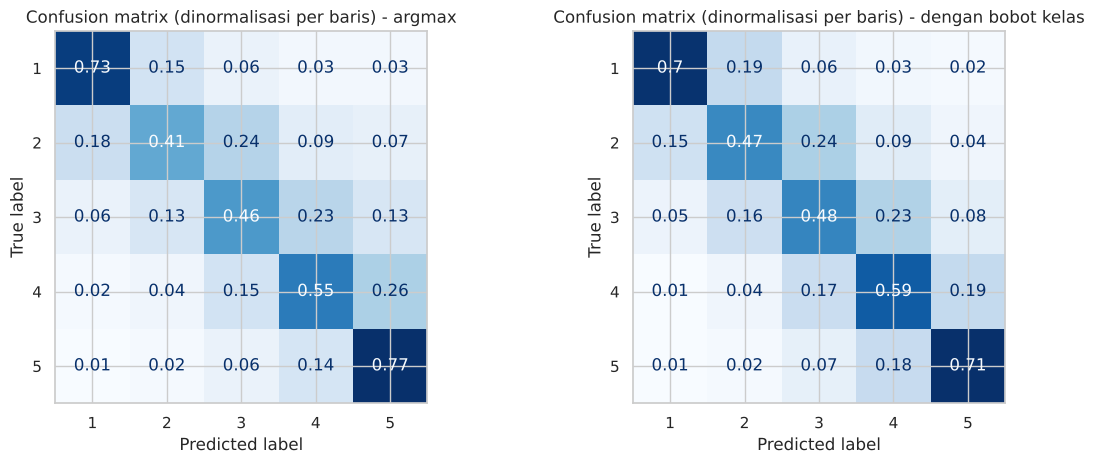

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (title, pred) in zip(axes, [('argmax', oof.argmax(1)), ('dengan bobot kelas', (oof * w).argmax(1))]):
    ConfusionMatrixDisplay(confusion_matrix(y, pred, normalize='true').round(2), display_labels=[1,2,3,4,5]).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion matrix (dinormalisasi per baris) - {title}')
plt.tight_layout(); plt.savefig(FIG/'confusion_matrix.png', dpi=120); plt.show()

## 3. Feature importance (model final)

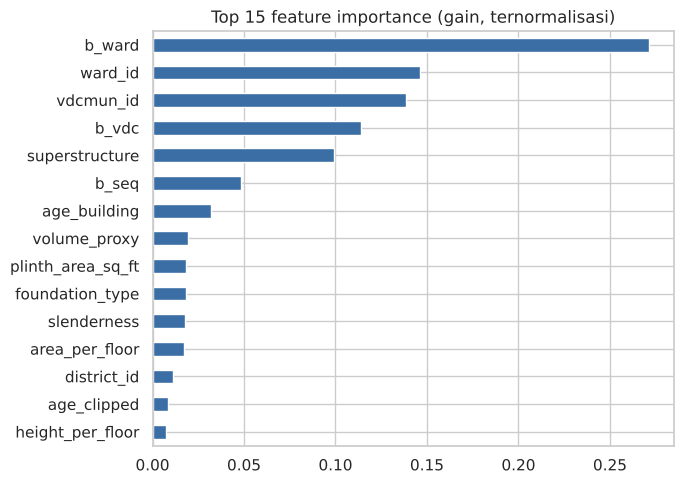

b_ward               0.271
ward_id              0.146
vdcmun_id            0.139
b_vdc                0.114
superstructure       0.099
b_seq                0.048
age_building         0.032
volume_proxy         0.019
plinth_area_sq_ft    0.018
foundation_type      0.018
dtype: float64

In [5]:
pipe = joblib.load(ROOT/'models'/'pipeline_model_lgbm.pkl')
names = pipe[:-1].transform(train.drop(columns=['damage_grade']).head(2)).columns
imp = pd.Series(pipe[-1].booster_.feature_importance('gain'), index=names).sort_values()
ax = (imp / imp.sum()).tail(15).plot.barh(figsize=(7, 5), color='#3b6ea5'); ax.set_title('Top 15 feature importance (gain, ternormalisasi)')
plt.tight_layout(); plt.savefig(FIG/'feature_importance.png', dpi=130); plt.show()
(imp / imp.sum()).sort_values(ascending=False).head(10).round(3)